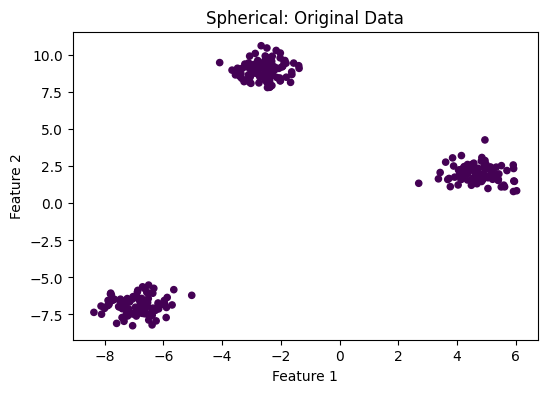

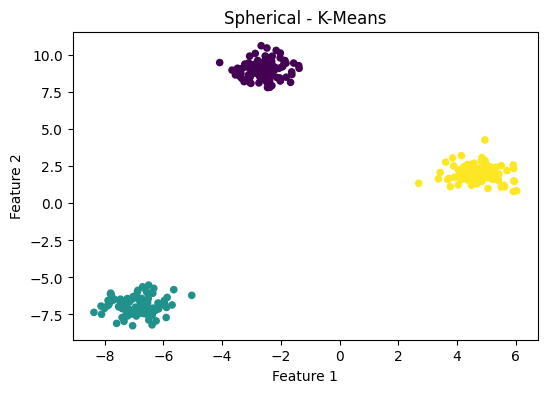

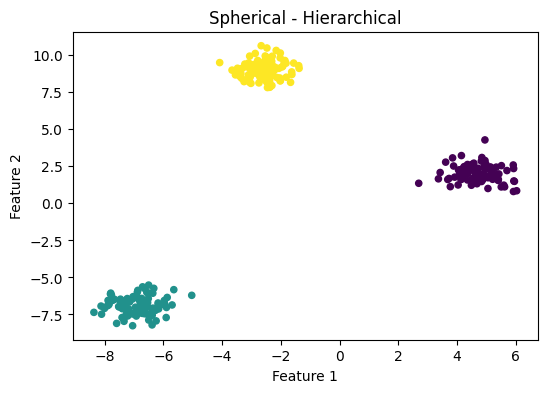

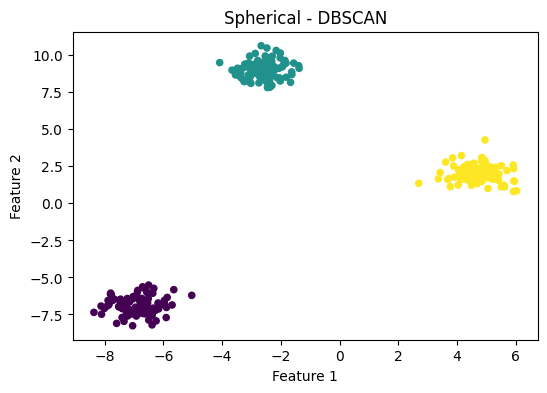

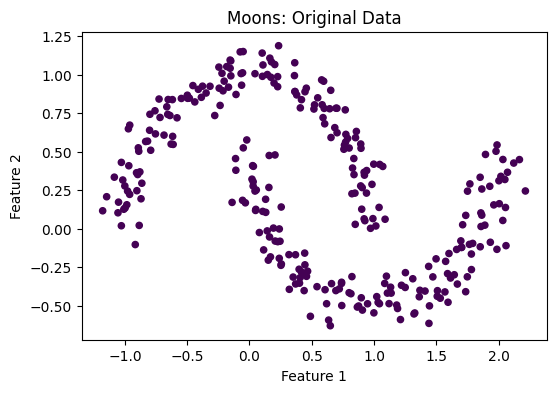

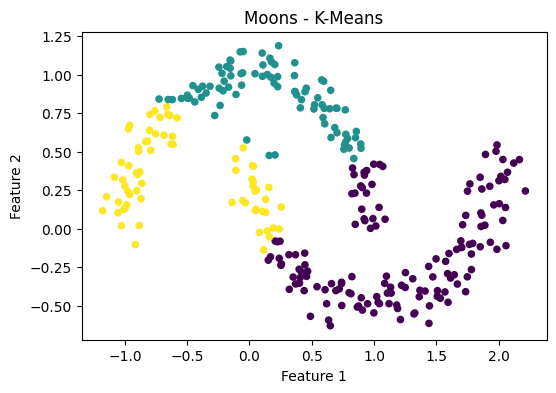

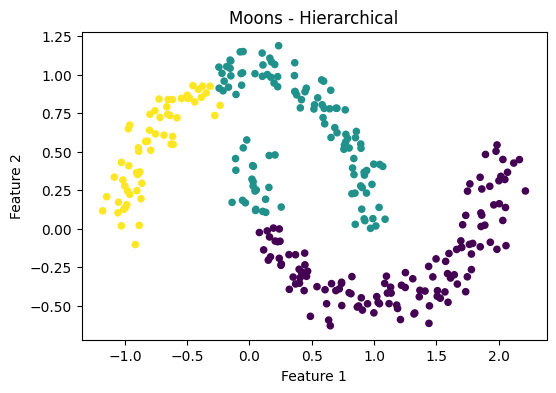

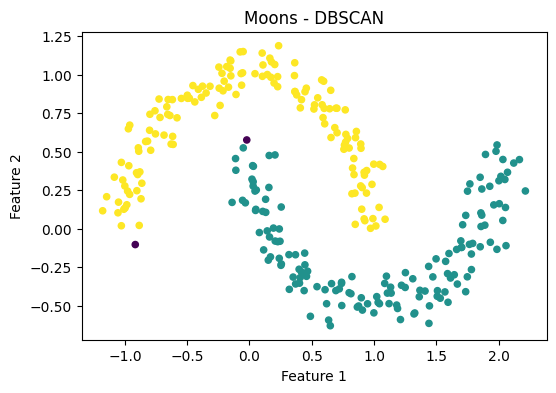

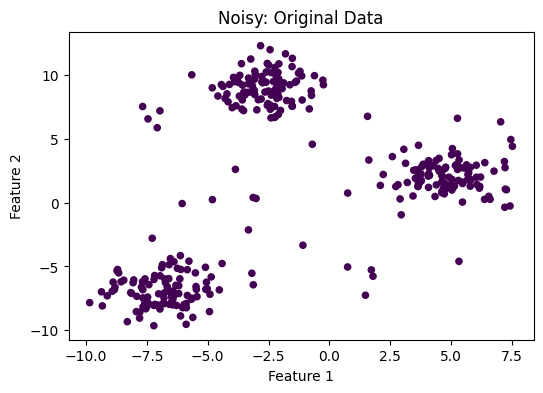

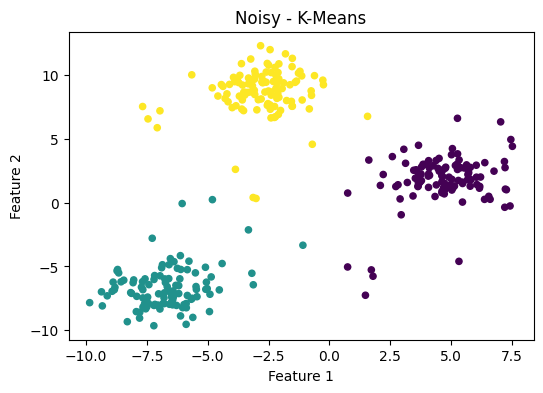

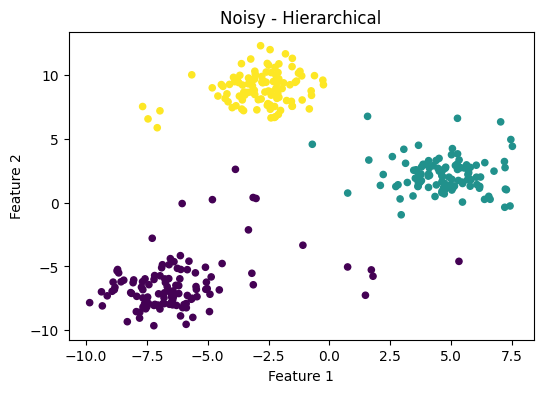

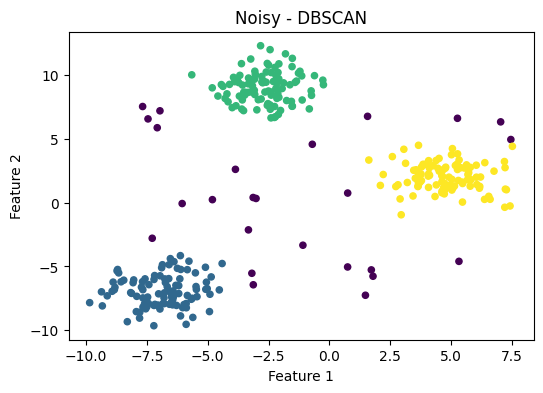


Clustering Comparison:
  Dataset    Algorithm  Number of Clusters  Noise Points  Silhouette Score
Spherical      K-Means                   3             0            0.9085
Spherical Hierarchical                   3             0            0.9085
Spherical       DBSCAN                   3             0            0.9085
    Moons      K-Means                   3             0            0.4350
    Moons Hierarchical                   3             0            0.3814
    Moons       DBSCAN                   2             2            0.3868
    Noisy      K-Means                   3             0            0.7602
    Noisy Hierarchical                   3             0            0.7491
    Noisy       DBSCAN                   3            25            0.8190

Standardized Data Comparison:
Spherical | K-Means | Silhouette Score: 0.9085
Spherical | Hierarchical | Silhouette Score: 0.9085
Spherical | DBSCAN | Silhouette Score: 0.9085
Moons | K-Means | Silhouette Score: 0.4350
Moons |

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs, make_moons
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

X1, _ = make_blobs(
    n_samples=300, centers=3,
    cluster_std=0.6, random_state=42
)

X2, _ = make_moons(
    n_samples=300, noise=0.08,
    random_state=42
)

X3, _ = make_blobs(
    n_samples=300, centers=3,
    cluster_std=1.2, random_state=42
)

rng = np.random.RandomState(42)
noise = rng.uniform(
    low=[-8, -8], high=[8, 8], size=(30, 2)
)
X3 = np.vstack([X3, noise])

datasets = {
    "Spherical": X1,
    "Moons": X2,
    "Noisy": X3
}

def plot_clusters(X, labels, title):
    plt.figure(figsize=(6, 4))
    plt.scatter(
        X[:, 0], X[:, 1],
        c=labels, cmap="viridis", s=20
    )
    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()

results = []

for dataset_name, X in datasets.items():
    X_scaled = StandardScaler().fit_transform(X)

    plot_clusters(X, np.zeros(len(X)), f"{dataset_name}: Original Data")

    models = {
        "K-Means": KMeans(
            n_clusters=3, random_state=42, n_init=10
        ),
        "Hierarchical": AgglomerativeClustering(
            n_clusters=3
        ),
        "DBSCAN": DBSCAN(
            eps=0.25, min_samples=5
        )
    }

    for algorithm, model in models.items():
        labels = model.fit_predict(X_scaled)

        clusters = set(labels) - {-1}
        n_clusters = len(clusters)
        n_noise = int(np.sum(labels == -1))

        valid = labels != -1
        valid_labels = labels[valid]

        if len(set(valid_labels)) >= 2 and len(set(valid_labels)) < len(valid_labels):
            score = silhouette_score(
                X_scaled[valid], valid_labels
            )
        else:
            score = np.nan

        results.append([
            dataset_name, algorithm,
            n_clusters, n_noise, score
        ])

        plot_clusters(
            X, labels,
            f"{dataset_name} - {algorithm}"
        )

results_df = pd.DataFrame(
    results,
    columns=[
        "Dataset", "Algorithm", "Number of Clusters",
        "Noise Points", "Silhouette Score"
    ]
)

print("\nClustering Comparison:")
print(results_df.round(4).to_string(index=False))

print("\nStandardized Data Comparison:")

for dataset_name, X in datasets.items():
    X_scaled = StandardScaler().fit_transform(X)

    models = {
        "K-Means": KMeans(
            n_clusters=3, random_state=42, n_init=10
        ),
        "Hierarchical": AgglomerativeClustering(
            n_clusters=3
        ),
        "DBSCAN": DBSCAN(
            eps=0.25, min_samples=5
        )
    }

    for algorithm, model in models.items():
        labels = model.fit_predict(X_scaled)
        valid = labels != -1
        valid_labels = labels[valid]

        if len(set(valid_labels)) >= 2 and len(set(valid_labels)) < len(valid_labels):
            score = silhouette_score(
                X_scaled[valid], valid_labels
            )
        else:
            score = np.nan

        print(
            f"{dataset_name} | {algorithm} | "
            f"Silhouette Score: {score:.4f}"
            if not np.isnan(score)
            else f"{dataset_name} | {algorithm} | Silhouette Score: N/A"
        )
